# Notions interactives — un atelier transversal

**Série cross-series** · Atelier Python · Dix notions, sept séries, un curseur par notion

Ce carnet ne remplace aucun carnet de série : il les **traverse**. Dix notions-clés du cursus
sont reprises ici sous la même forme — une figure qui montre l'effet sur plusieurs valeurs, puis
un **widget** où c'est vous qui faites varier le paramètre. L'objectif n'est pas d'apprendre la
notion (chaque série le fait mieux qu'ici) mais de sentir, en un geste, **ce que le paramètre
change**.

## Objectifs d'apprentissage

À la fin de ce carnet, vous saurez :

1. nommer le paramètre qui gouverne chacune des dix notions, et prédire le sens de son effet ;
2. reconnaître un effet **monotone** (température d'échantillonnage), un effet **à seuil**
   (satisfiabilité 3-SAT, équilibre de Nash) et un effet **à optimum** (pas d'apprentissage,
   seuil de décision, epsilon-greedy) ;
3. expliquer pourquoi une figure statique à plusieurs valeurs suffit à démontrer un effet, et
   pourquoi le widget ne fait qu'y ajouter le geste.

## Prérequis

- Python 3, `numpy`, `matplotlib` ; `ipywidgets` pour la partie manipulable.
- Aucune connaissance préalable des dix domaines : chaque notion est présentée en trois phrases
  avant son code.

## Durée estimée

45 à 60 minutes en lecture active, dont 15 minutes de manipulation des widgets.

## Navigation

| Bloc | Notions | Série d'origine |
|------|---------|-----------------|
| Échantillonnage | 1 et 2 | GenAI |
| Apprentissage supervisé | 3 et 4 | ML |
| Inférence bayésienne | 5 et 6 | Probas |
| Recherche et décision | 7 | Search |
| Apprentissage par renforcement | 8 | RL |
| Théorie des jeux | 9 | GameTheory |
| Complexité | 10 | Complexity |

Exercices : un après la notion 3, un après la notion 6, un après la notion 9.

## Comment lire ce carnet

Chaque notion occupe quatre cellules, toujours dans le même ordre :

1. **l'enjeu** — ce que la notion décide, en trois phrases ;
2. **la figure statique** — la même expérience à plusieurs valeurs du paramètre, committée avec
   le carnet : c'est cette figure qui démontre l'effet sur GitHub, sur le site et dans un rendu
   hors ligne, car aucun de ces lecteurs n'exécute de widget ;
3. **la lecture** — ce que la figure montre, valeurs à l'appui, et le geste à faire ensuite ;
4. **le widget** — un curseur qui rejoue l'expérience en direct.

Le carnet se lit donc deux fois : d'abord les figures (ce que tout le monde voit), ensuite les
widgets (ce que vous seul voyez, en exécutant).

**Mode batch.** La cellule ci-dessous définit `BATCH_MODE`. Quand il vaut `True` — le cas d'une
exécution automatisée — les widgets ne sont pas affichés : chaque cellule de widget calcule à la
place la valeur par défaut et l'imprime. Pour manipuler, passez `BATCH_MODE` à `False` et
relancez la cellule.

## 0. Réglages communs

Une seule cellule de paramètres, taguée `parameters` : c'est elle que Papermill remplace quand on
injecte des valeurs. Elle fixe aussi le style des figures, pour que les dix blocs se lisent comme
un seul document.

In [1]:
# Parametres injectables (tag `parameters` : Papermill insere ses valeurs juste apres).
BATCH_MODE = True

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})
print(f"Reglages charges : BATCH_MODE = {BATCH_MODE}, numpy {np.__version__}, "
      f"matplotlib {plt.matplotlib.__version__}")

Reglages charges : BATCH_MODE = True, numpy 2.4.2, matplotlib 3.10.8


## 1. La température d'échantillonnage

*Série d'origine : GenAI.*

Un modèle de langage ne choisit pas le mot le plus probable : il **tire** dans une
distribution. La température divise les logits avant le softmax. Petite, elle rend la
distribution pointue et la génération répétitive ; grande, elle l'aplatit et la génération devient
vagabonde. C'est le paramètre le plus utilisé — et le moins discuté — de toute la génération de
texte.

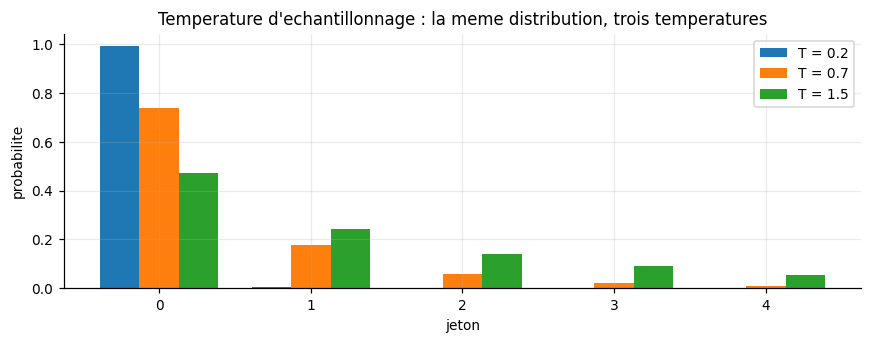

T = 0.2 -> p_max = 0.993, entropie = 0.041 nats
T = 0.7 -> p_max = 0.738, entropie = 0.810 nats
T = 1.5 -> p_max = 0.471, entropie = 1.351 nats


In [3]:
# LOGITS : scores bruts (non normalises) d'un pas de generation a 5 jetons candidats.
LOGITS = np.array([2.0, 1.0, 0.2, -0.5, -1.2])
# Trois regimes : T < 1 concentre la masse, T = 1 laisse la distribution brute, T > 1 l'aplatit.
TEMPERATURES = [0.2, 0.7, 1.5]


def distribution(logits, temperature):
    """Softmax des logits divises par la temperature."""
    z = logits / temperature
    # Retrancher le max ne change pas le softmax mais evite un debordement de exp sur de grands logits.
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()


def entropie(p):
    """Entropie de Shannon, en nats."""
    return float(-(p * np.log(p)).sum())


fig, ax = plt.subplots(figsize=(8.0, 3.2))
largeur = 0.26
for rang, temperature in enumerate(TEMPERATURES):
    p = distribution(LOGITS, temperature)
    ax.bar(np.arange(len(LOGITS)) + (rang - 1) * largeur, p, width=largeur,
           label=f"T = {temperature}")
ax.set_xlabel("jeton")
ax.set_ylabel("probabilite")
ax.set_xticks(range(len(LOGITS)))
ax.set_title("Temperature d'echantillonnage : la meme distribution, trois temperatures")
ax.legend()
fig.tight_layout()
plt.show()

p_froid = distribution(LOGITS, 0.2)
p_tiede = distribution(LOGITS, 0.7)
p_chaud = distribution(LOGITS, 1.5)
print(f"T = 0.2 -> p_max = {p_froid.max():.3f}, entropie = {entropie(p_froid):.3f} nats")
print(f"T = 0.7 -> p_max = {p_tiede.max():.3f}, entropie = {entropie(p_tiede):.3f} nats")
print(f"T = 1.5 -> p_max = {p_chaud.max():.3f}, entropie = {entropie(p_chaud):.3f} nats")

### Lecture du résultat

Le jeton le plus probable porte **0.993** de la masse à `T = 0.2`, contre **0.471** à
`T = 1.5`. Même distribution, deux comportements opposés : à froid le modèle répond presque
toujours la même chose, à chaud il explore. L'entropie le résume en un nombre — **0.041**
nats à `T = 0.2`, **0.810** à `T = 0.7`, **1.351** à `T = 1.5` — et sa croissance est
**monotone**, ce qui est exactement le sens de l'effet.

**À manipuler.** Le curseur va de `T = 0.05` à `T = 3.0`. Cherchez la température où le deuxième
jeton dépasserait le premier : elle n'existe pas sur ces logits, et c'est le point — la
température **aplatit** une hiérarchie, elle ne la réordonne pas.

In [4]:
# Callback du widget : recalcule et redessine la distribution pour une temperature donnee.
def _montre_temperature(temperature=0.7):
    p = distribution(LOGITS, temperature)
    fig, ax = plt.subplots(figsize=(7.0, 2.6))
    ax.bar(np.arange(len(LOGITS)), p)
    ax.set_ylim(0, 1)
    ax.set_xticks(range(len(LOGITS)))
    ax.set_title(f"T = {temperature:.2f} -- p_max = {p.max():.3f}, "
                 f"entropie = {entropie(p):.3f} nats")
    plt.show()


# En mode batch (CI, Papermill), pas de widget : un resume imprime le meme contenu.
if BATCH_MODE:
    _p = distribution(LOGITS, 0.7)
    print(f"Mode batch : widget non affiche. A T = 0.7, p_max = {_p.max():.3f}, "
          f"entropie = {entropie(_p):.3f} nats")
else:
    interact(_montre_temperature,
             temperature=FloatSlider(value=0.7, min=0.05, max=3.0, step=0.05, description="T"))

Mode batch : widget non affiche. A T = 0.7, p_max = 0.738, entropie = 0.810 nats


## 2. Le noyau top-p

*Série d'origine : GenAI.*

Top-p répond à une autre question que la température : non pas « comment aplatir », mais
« où couper la queue ». On trie les jetons par probabilité décroissante et l'on garde le plus
petit ensemble dont la masse cumulée atteint `p` ; le reste est éliminé, puis on renormalise.
C'est le réglage qui empêche un modèle de tirer un jeton improbable sans pour autant le rendre
uniforme.

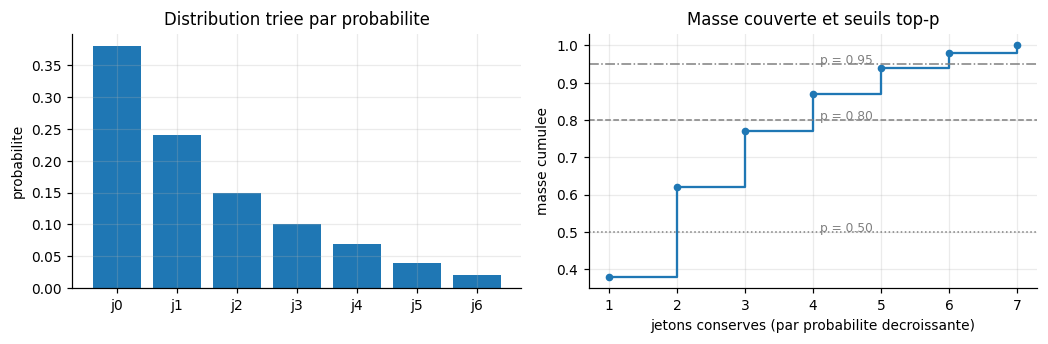

p = 0.50 -> noyau de 2 jetons, masse couverte 0.620
p = 0.80 -> noyau de 4 jetons, masse couverte 0.870
p = 0.95 -> noyau de 6 jetons, masse couverte 0.980


In [5]:
# Distribution deja normalisee d'un pas de generation a 7 jetons candidats (masse totale 1).
PROBS = np.array([0.38, 0.24, 0.15, 0.10, 0.07, 0.04, 0.02])
JETONS = [f"j{i}" for i in range(len(PROBS))]
# Trois seuils top-p usuels : 0.50 agressif, 0.80 courant, 0.95 quasi complet.
SEUILS = [0.50, 0.80, 0.95]


def noyau(probs, seuil):
    """Plus petit ensemble de jetons dont la masse cumulee atteint le seuil."""
    # Trier par probabilite decroissante : le noyau top-p est toujours un prefixe de ce tri.
    ordre = np.argsort(probs)[::-1]
    cumul = np.cumsum(probs[ordre])
    k = int(np.searchsorted(cumul, seuil) + 1)
    k = min(k, len(probs))
    return ordre[:k], float(cumul[k - 1])


ordre = np.argsort(PROBS)[::-1]
cumul = np.cumsum(PROBS[ordre])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.2))
ax1.bar(range(len(PROBS)), PROBS[ordre])
ax1.set_xticks(range(len(PROBS)))
ax1.set_xticklabels([JETONS[i] for i in ordre])
ax1.set_title("Distribution triee par probabilite")
ax1.set_ylabel("probabilite")

ax2.step(range(1, len(PROBS) + 1), cumul, where="post", marker="o", markersize=4)
for seuil, style in zip(SEUILS, (":", "--", "-.")):
    ax2.axhline(seuil, linestyle=style, linewidth=1.0, color="gray")
    ax2.annotate(f"p = {seuil:.2f}", xy=(4.1, seuil), fontsize=8, color="gray")
ax2.set_xlabel("jetons conserves (par probabilite decroissante)")
ax2.set_ylabel("masse cumulee")
ax2.set_title("Masse couverte et seuils top-p")
fig.tight_layout()
plt.show()

for seuil in SEUILS:
    indices, masse = noyau(PROBS, seuil)
    print(f"p = {seuil:.2f} -> noyau de {len(indices)} jetons, masse couverte {masse:.3f}")
    etiquette = int(round(seuil * 100))

### Lecture du résultat

À `p = 0.50`, le noyau ne garde que **2** jetons et couvre **0.620** de la masse ; à
`p = 0.80` il en faut **4** pour **0.870**, et à `p = 0.95`, **6** pour **0.980**. La
croissance n'est pas linéaire : les derniers points de masse coûtent cher, parce que la
distribution a une queue longue. C'est pourquoi top-p et température ne se remplacent pas —
`T` change la **forme** de la distribution, `p` coupe sa **queue**.

**À manipuler.** Poussez `p` vers `1.0` : le noyau devient la distribution entière, et top-p ne
filtre plus rien. Descendez vers `0.10` : un seul jeton reste. Le seuil utile est celui où la
courbe de masse cumulée s'aplatit.

In [6]:
# Callback du widget : met en evidence les jetons retenus par le noyau top-p pour un seuil donne.
def _montre_noyau(seuil=0.80):
    indices, masse = noyau(PROBS, seuil)
    retenus = [JETONS[i] for i in indices]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 2.8))
    # Bleu pour les jetons du noyau, gris clair pour les jetons ecartes.
    couleur = ["tab:blue" if i in set(indices) else "lightgray" for i in range(len(PROBS))]
    ax1.bar(range(len(PROBS)), PROBS, color=couleur)
    ax1.set_xticks(range(len(PROBS)))
    ax1.set_xticklabels(JETONS)
    ax1.set_title(f"p = {seuil:.2f} : {len(indices)} jetons retenus ({', '.join(retenus)})")
    ax2.step(range(1, len(PROBS) + 1), cumul, where="post", marker="o", markersize=4)
    ax2.axhline(seuil, linestyle=":", color="gray")
    ax2.set_title(f"masse couverte {masse:.3f}")
    plt.show()


if BATCH_MODE:
    _indices, _masse = noyau(PROBS, 0.80)
    print(f"Mode batch : widget non affiche. A p = 0.80, noyau de {len(_indices)} jetons, "
          f"masse couverte {_masse:.3f}")
else:
    interact(_montre_noyau, seuil=FloatSlider(value=0.80, min=0.10, max=1.0, step=0.05,
                                              description="p"))

Mode batch : widget non affiche. A p = 0.80, noyau de 4 jetons, masse couverte 0.870


## 3. Le pas d'apprentissage

*Série d'origine : ML.*

La descente de gradient avance à contre-pente, d'une distance fixée par le **pas
d'apprentissage**. Trop petit, elle converge mais coûte des milliers d'itérations ; trop grand,
elle rebondit d'un côté à l'autre et diverge. C'est la notion la plus concrète de l'optimisation :
une seule constante décide si l'entraînement aboutit.

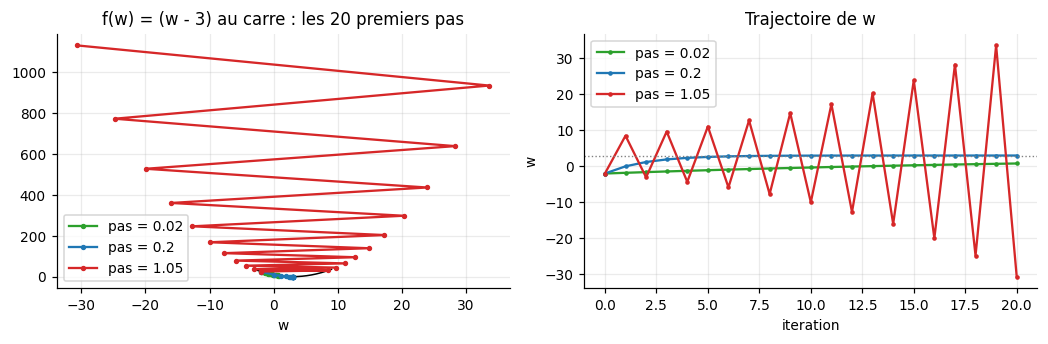

pas = 0.02  -> w(20) =   +0.7900, |w - 3| = 2.2100
pas = 0.2   -> w(20) =   +2.9998, |w - 3| = 0.0002
pas = 1.05  -> w(20) =  -30.6375, |w - 3| = 33.6375


In [7]:
# CIBLE : minimum de f(w) = (w - 3)^2 ; W0 : point de depart commun aux trois experiences.
CIBLE = 3.0
W0 = -2.0
# Trois pas : convergence lente, convergence rapide, et un pas au-dela de la limite de stabilite (pas > 1).
PAS = [0.02, 0.2, 1.05]
ITERATIONS = 20


def descente(pas, iterations=ITERATIONS, w0=W0):
    """Descente de gradient sur f(w) = (w - 3)^2, de gradient 2(w - 3)."""
    w = w0
    trace = [w]
    for _ in range(iterations):
        w = w - pas * 2.0 * (w - CIBLE)
        trace.append(w)
    return np.array(trace)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.2))
grille = np.linspace(-3.0, 9.0, 300)
ax1.plot(grille, (grille - CIBLE) ** 2, color="black", linewidth=1.0)
for pas, couleur in zip(PAS, ("tab:green", "tab:blue", "tab:red")):
    trace = descente(pas)
    # Chaque trace est la suite des w successifs, vue sur la courbe de f puis sur sa trajectoire.
    ax1.plot(trace, (trace - CIBLE) ** 2, marker=".", markersize=5, color=couleur,
             label=f"pas = {pas}")
    ax2.plot(trace, marker=".", markersize=4, color=couleur, label=f"pas = {pas}")
ax1.set_xlabel("w")
ax1.set_title("f(w) = (w - 3) au carre : les 20 premiers pas")
ax1.legend()
ax2.axhline(CIBLE, linestyle=":", color="gray", linewidth=0.9)
ax2.set_xlabel("iteration")
ax2.set_ylabel("w")
ax2.set_title("Trajectoire de w")
ax2.legend()
fig.tight_layout()
plt.show()

traces = {pas: descente(pas) for pas in PAS}
for pas in PAS:
    w_final = traces[pas][-1]
    print(f"pas = {pas:<5} -> w(20) = {w_final:+9.4f}, |w - 3| = {abs(w_final - CIBLE):.4f}")

### Lecture du résultat

Trois régimes, un seul paramètre. À `pas = 0.02`, la position finale vaut **+0.7900** : l'écart
à la cible 3 reste de **2.2100** après 20 itérations — la convergence est correcte mais lente.
À `pas = 0.2`, on est à **+2.9998**, soit un écart de **0.0002** : la zone utile. À `pas = 1.05`,
la trajectoire **diverge** : **-30.6375**, l'écart est de **33.6375**.

Le seuil est calculable : pour une quadratique de courbure `f'' = 2`, la descente est stable si
`pas < 2 / f'' = 1`. À `1.05`, on est au-delà, et aucune itération supplémentaire ne rattrape.
C'est un effet **à optimum** : trop petit coûte du temps, trop grand ne converge pas du tout.

**À manipuler.** Le curseur va jusqu'à `1.20`. Encadrez la divergence : à partir de quelle valeur
de pas la trajectoire quitte-t-elle définitivement la zone ? Comparez avec la prédiction
`2 / f'' = 1`.

In [8]:
# Callback du widget : relance la descente pour un pas donne et trace f(w) en echelle symlog.
def _montre_pas(pas=0.2):
    trace = descente(pas)
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    ax.plot((trace - CIBLE) ** 2, marker=".", markersize=4)
    ax.set_xlabel("iteration")
    ax.set_ylabel("f(w)")
    ax.set_title(f"pas = {pas:.3f} -- w(20) = {trace[-1]:+.4f}")
    # Echelle symlog : la convergence est geometrique, donc l'echelle log rend les derniers pas lisibles.
    ax.set_yscale("symlog", linthresh=1e-3)
    plt.show()


if BATCH_MODE:
    _trace = descente(0.2)
    print(f"Mode batch : widget non affiche. A pas = 0.2, w(20) = {_trace[-1]:+.4f}")
else:
    interact(_montre_pas,
             pas=FloatSlider(value=0.2, min=0.005, max=1.20, step=0.005, description="pas"))

Mode batch : widget non affiche. A pas = 0.2, w(20) = +2.9998


### Exercice 1 — la descente avec élan

La descente simple s'arrête de progresser dès que le gradient s'aplatit, même loin de l'optimum.
L'**élan** (momentum) ajoute une vitesse qui accumule les gradients passés :

```
v <- beta * v - pas * gradient(w)
w <- w + v
```

**Objectif.** Implémenter `descente_elan(pas, beta, iterations)` pour la même fonction
`f(w) = (w - 3)^2`, puis comparer à la descente simple pour `pas = 0.02` : le nombre
d'itérations nécessaires pour que `|w - 3| < 0.01`.

**Indices.**
- `# Etape 1` : initialiser `w = W0` et `v = 0.0`.
- `# Etape 2` : à chaque itération, `v = beta * v - pas * 2.0 * (w - CIBLE)`, puis `w = w + v`.
- `# Etape 3` : renvoyer le tableau des positions et le nombre d'itérations avant le seuil.

In [9]:
def descente_elan(pas, beta, iterations=100, w0=W0):
    """Descente de gradient avec elan sur f(w) = (w - 3)^2."""
    trace = []
    iterations_avant_seuil = None
    # TODO etudiant : implementer les trois etapes decrites ci-dessus.
    return trace, iterations_avant_seuil


positions, nb = descente_elan(0.02, 0.9)
print("Exercice a completer")
print(f"positions collectees : {len(positions)}, iterations avant seuil : {nb}")

Exercice a completer
positions collectees : 0, iterations avant seuil : None


## 4. Le seuil de décision

*Série d'origine : ML.*

Un classifieur ne rend pas une étiquette mais un **score**. Le seuil transforme ce score
en décision, et déplacer le seuil échange systématiquement de la précision contre du rappel.
C'est le seul paramètre d'un modèle déjà entraîné — et celui qui décide de ce que le modèle fait
vraiment en production.

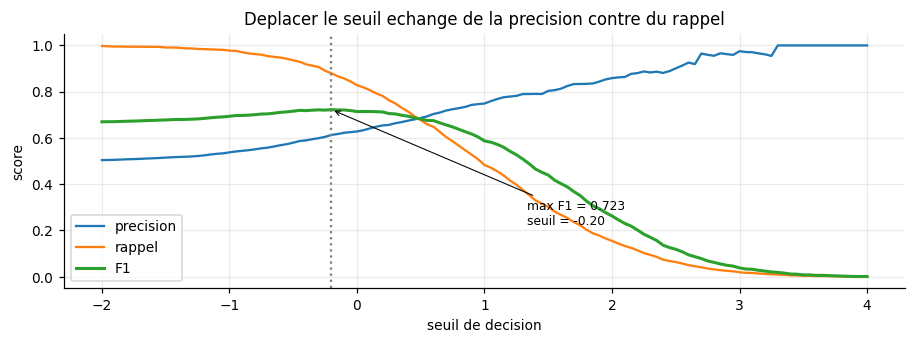

seuil max F1   = -0.20 -> P = 0.613, R = 0.879, F1 = 0.723
seuil P = R    = 0.50 -> P = R = 0.686
seuil 0.00     -> P = 0.628, R = 0.828


In [10]:
RNG = np.random.default_rng(0)
N_PAR_CLASSE = 2000
# Deux classes de scores : positifs autour de 1.0, negatifs autour de 0.0, meme ecart-type 1.0.
POSITIFS = RNG.normal(1.0, 1.0, N_PAR_CLASSE)
NEGATIFS = RNG.normal(0.0, 1.0, N_PAR_CLASSE)
# Grille de seuils balayee de -2.0 a 4.0 : on deplace la frontiere de decision pour voir l'echange P/R.
SEUILS = np.linspace(-2.0, 4.0, 121)


def courbes_seuil(positifs, negatifs, seuils):
    """Precision, rappel et F1 pour chaque seuil de decision."""
    precision, rappel, f1 = [], [], []
    for seuil in seuils:
        # Un echantillon est predit positif quand son score depasse le seuil courant.
        vrais_positifs = int((positifs >= seuil).sum())
        faux_positifs = int((negatifs >= seuil).sum())
        p = vrais_positifs / (vrais_positifs + faux_positifs) if vrais_positifs + faux_positifs else 1.0
        r = vrais_positifs / len(positifs)
        precision.append(p)
        rappel.append(r)
        f1.append(2 * p * r / (p + r) if p + r else 0.0)
    return np.array(precision), np.array(rappel), np.array(f1)


precision, rappel, f1 = courbes_seuil(POSITIFS, NEGATIFS, SEUILS)
# Le seuil retenu maximise F1, moyenne harmonique de la precision et du rappel.
meilleur = int(np.argmax(f1))

fig, ax = plt.subplots(figsize=(8.4, 3.2))
ax.plot(SEUILS, precision, label="precision")
ax.plot(SEUILS, rappel, label="rappel")
ax.plot(SEUILS, f1, label="F1", linewidth=2.0)
ax.axvline(SEUILS[meilleur], linestyle=":", color="gray")
ax.annotate(f"max F1 = {f1[meilleur]:.3f}\nseuil = {SEUILS[meilleur]:.2f}",
            xy=(SEUILS[meilleur], f1[meilleur]), xytext=(0.55, 0.25),
            textcoords="axes fraction", fontsize=8,
            arrowprops={"arrowstyle": "->", "linewidth": 0.7})
ax.set_xlabel("seuil de decision")
ax.set_ylabel("score")
ax.set_title("Deplacer le seuil echange de la precision contre du rappel")
ax.legend()
fig.tight_layout()
plt.show()

egalite = int(np.argmin(np.abs(precision - rappel)))
print(f"seuil max F1   = {SEUILS[meilleur]:.2f} -> P = {precision[meilleur]:.3f}, "
      f"R = {rappel[meilleur]:.3f}, F1 = {f1[meilleur]:.3f}")
print(f"seuil P = R    = {SEUILS[egalite]:.2f} -> P = R = {precision[egalite]:.3f}")
print(f"seuil 0.00     -> P = {precision[np.argmin(np.abs(SEUILS))]:.3f}, "
      f"R = {rappel[np.argmin(np.abs(SEUILS))]:.3f}")

### Lecture du résultat

Le maximum de F1 tombe au seuil **-0.20**, avec précision **0.613** et rappel
**0.879** — soit `F1 = ` **0.723**. Précision et rappel se croisent au seuil
**0.50**, où les deux valent **0.686** : au-delà, gagner de la précision coûte plus
de rappel qu'on n'en gagne.

Ce maximum est **à gauche** du croisement, et ce n'est pas une anomalie : entre `0.50` et
`-0.20`, la précision perd `0.686 - 0.613` quand le rappel gagne `0.879 - 0.686`.
La moyenne harmonique pèse les deux termes, mais elle est dominée par le plus faible : un rappel
qui monte vers son plafond rattrape sans peine une précision qui ne s'effondre pas encore.

Aucun seuil n'est « le bon » dans l'absolu : il se choisit contre un coût. Un dépistage médical
préfère le rappel (rater un malade coûte plus qu'une fausse alerte) et se place à gauche du
maximum de F1 ; un filtre anti-spam préfère la précision et se place à droite. La courbe ne dit
pas quoi choisir, elle dit ce que chaque choix coûte.

**À manipuler.** Le curseur affiche les trois compteurs (TP, FP, FN) en même temps que les trois
scores. Suivez le compteur qui bouge le plus quand vous déplacez le seuil d'un dixième.

In [11]:
# Callback du widget : histogramme des deux classes et droite du seuil, avec P, R, F1 recalcules.
def _montre_seuil(seuil=0.5):
    vrais_positifs = int((POSITIFS >= seuil).sum())
    faux_positifs = int((NEGATIFS >= seuil).sum())
    # FN : positifs rates par le seuil ; les trois compteurs TP/FP/FN suffisent a reconstruire P et R.
    faux_negatifs = N_PAR_CLASSE - vrais_positifs
    p = vrais_positifs / max(vrais_positifs + faux_positifs, 1)
    r = vrais_positifs / N_PAR_CLASSE
    f = 2 * p * r / (p + r) if p + r else 0.0
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    ax.hist(NEGATIFS, bins=60, alpha=0.55, label="negatifs")
    ax.hist(POSITIFS, bins=60, alpha=0.55, label="positifs")
    ax.axvline(seuil, color="black", linewidth=1.5)
    ax.set_title(f"seuil {seuil:.2f} -- P = {p:.3f}, R = {r:.3f}, F1 = {f:.3f} "
                 f"(TP {vrais_positifs}, FP {faux_positifs}, FN {faux_negatifs})")
    ax.legend()
    plt.show()


if BATCH_MODE:
    _seuil = 0.5
    _vp = int((POSITIFS >= _seuil).sum())
    _fp = int((NEGATIFS >= _seuil).sum())
    print(f"Mode batch : widget non affiche. A seuil 0.50, TP = {_vp}, FP = {_fp}")
else:
    interact(_montre_seuil,
             seuil=FloatSlider(value=0.5, min=-2.0, max=4.0, step=0.05, description="seuil"))

Mode batch : widget non affiche. A seuil 0.50, TP = 1355, FP = 619


## 5. La mise à jour bayésienne Beta

*Série d'origine : Probas.*

Un prior `Beta(a, b)` représente une croyance sur un taux de succès ; chaque observation
le met à jour en ajoutant un pseudo-compte. Le posterior reste une Beta, sa moyenne se déplace vers
la fréquence observée et sa largeur diminue à mesure que les données s'accumulent. C'est le
modèle conjugué le plus simple — et le seul qu'on puisse dessiner entièrement à la main.

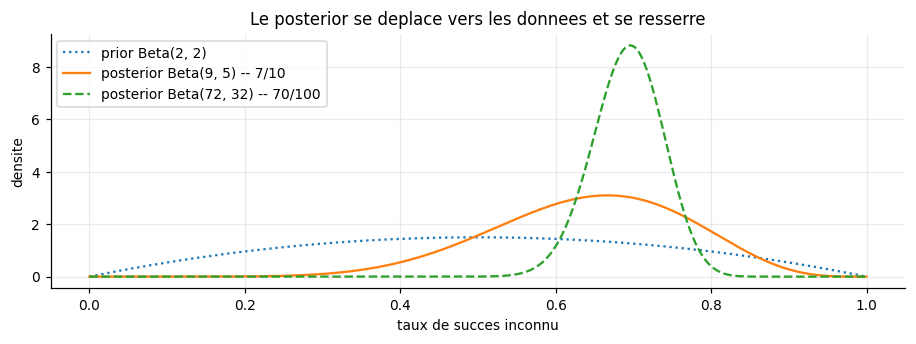

 prior : moyenne = 0.500, IC 95 % = [0.094, 0.906], largeur = 0.812
  7/10 : moyenne = 0.643, IC 95 % = [0.386, 0.861], largeur = 0.476
70/100 : moyenne = 0.692, IC 95 % = [0.601, 0.777], largeur = 0.176


In [12]:
import math

# Grille fine sur (0, 1) : la densite Beta y est evaluee puis normalisee par somme, sans scipy.
GRILLE = np.linspace(1e-4, 1.0 - 1e-4, 2000)


def densite_beta(x, a, b):
    """Densite Beta(a, b) sans scipy : le log de la constante suffit."""
    log_norm = math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b)
    log_densite = (a - 1) * np.log(x) + (b - 1) * np.log1p(-x) - log_norm
    return np.exp(log_densite)


def intervalle_credibilite(x, densite, niveau=0.95):
    """Intervalle central a 95 % par somme cumulee sur la grille."""
    masse = densite / densite.sum()
    cumul = np.cumsum(masse)
    bas = x[np.searchsorted(cumul, (1 - niveau) / 2)]
    haut = x[np.searchsorted(cumul, 1 - (1 - niveau) / 2)]
    return float(bas), float(haut)


# Prior Beta(2, 2) : centre sur 0.5, equivalent a deux succes et deux echecs fictifs.
PRIOR = (2.0, 2.0)
SUCCES, ESSAIS = 7, 10
# Conjugaison Beta-Binomial : posterior = Beta(a + succes, b + echecs) apres 7 succes sur 10 essais.
POSTERIOR = (PRIOR[0] + SUCCES, PRIOR[1] + ESSAIS - SUCCES)
# Meme prior apres 70 succes sur 100 essais : le posterior se resserre autour de 0.7.
APRES_BEAUCOUP = (PRIOR[0] + 70, PRIOR[1] + 30)

fig, ax = plt.subplots(figsize=(8.4, 3.2))
for (a, b), etiquette, style in (
    (PRIOR, f"prior Beta({PRIOR[0]:.0f}, {PRIOR[1]:.0f})", ":"),
    (POSTERIOR, f"posterior Beta({POSTERIOR[0]:.0f}, {POSTERIOR[1]:.0f}) -- 7/10", "-"),
    (APRES_BEAUCOUP, f"posterior Beta({APRES_BEAUCOUP[0]:.0f}, {APRES_BEAUCOUP[1]:.0f}) -- 70/100", "--"),
):
    ax.plot(GRILLE, densite_beta(GRILLE, a, b), linestyle=style, label=etiquette)
ax.set_xlabel("taux de succes inconnu")
ax.set_ylabel("densite")
ax.set_title("Le posterior se deplace vers les donnees et se resserre")
ax.legend()
fig.tight_layout()
plt.show()

lignes = []
for (a, b), etiquette in ((PRIOR, "prior"), (POSTERIOR, "7/10"), (APRES_BEAUCOUP, "70/100")):
    densite = densite_beta(GRILLE, a, b)
    bas, haut = intervalle_credibilite(GRILLE, densite)
    moyenne = a / (a + b)
    lignes.append((etiquette, moyenne, bas, haut))
    print(f"{etiquette:>6} : moyenne = {moyenne:.3f}, IC 95 % = [{bas:.3f}, {haut:.3f}], "
          f"largeur = {haut - bas:.3f}")

### Lecture du résultat

Le prior `Beta(2, 2)` est centré sur **0.500** avec un intervalle de crédibilité à 95 %
large de **0.812** : on ne savait presque rien. Après 7 succès sur 10, le posterior
`Beta(9, 5)` se centre sur **0.643**, avec un intervalle **[0.386, 0.861]**,
large de **0.476**. Après 70 succès sur 100 — même fréquence observée — la largeur
tombe à **0.176**.

Deux choses bougent ensemble et il faut les distinguer : la **position** suit les données,
l'**épaisseur** suit le nombre de données. Un posterior étroit n'est pas plus « vrai » qu'un
large : il est seulement mieux informé.

**À manipuler.** Les deux curseurs sont les pseudo-comptes `a` et `b` du prior. Avec `a = b`, la
moyenne reste à `0.5` quelle que soit la hauteur — c'est la **force** du prior qui change, pas son
centre. Avec `a = 60, b = 1`, la moyenne affichée reste à `0.98` : ce prior pèserait soixante et
une observations contre dix, et les mêmes tirages ne déplaceraient le posterior que de quelques
centièmes. C'est la **force** du prior qui décide, pas son centre.

In [13]:
# Callback du widget : densite Beta(a, b), intervalle de credibilite a 95 % et moyenne a / (a + b).
def _montre_beta(a=9.0, b=5.0):
    densite = densite_beta(GRILLE, a, b)
    bas, haut = intervalle_credibilite(GRILLE, densite)
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    ax.plot(GRILLE, densite)
    # axvspan ombre l'intervalle central ; axvline marque la moyenne du posterior.
    ax.axvspan(bas, haut, alpha=0.2, label=f"IC 95 % [{bas:.2f}, {haut:.2f}]")
    ax.axvline(a / (a + b), color="black", linewidth=1.2, label=f"moyenne {a / (a + b):.3f}")
    ax.set_title(f"Beta({a:.0f}, {b:.0f}) -- moyenne {a / (a + b):.3f}, largeur {haut - bas:.3f}")
    ax.legend()
    plt.show()


if BATCH_MODE:
    _dens = densite_beta(GRILLE, 9.0, 5.0)
    _bas, _haut = intervalle_credibilite(GRILLE, _dens)
    print(f"Mode batch : widget non affiche. Beta(9, 5) -> moyenne 0.643, "
          f"IC 95 % [{_bas:.3f}, {_haut:.3f}]")
else:
    interact(_montre_beta,
             a=FloatSlider(value=9.0, min=1.0, max=60.0, step=1.0, description="a"),
             b=FloatSlider(value=5.0, min=1.0, max=60.0, step=1.0, description="b"))

Mode batch : widget non affiche. Beta(9, 5) -> moyenne 0.643, IC 95 % [0.386, 0.861]


## 6. L'acceptation dans Metropolis-Hastings

*Série d'origine : Probas.*

Metropolis-Hastings échantillonne une loi qu'on ne sait pas tirer directement : on
propose un déplacement, et on l'accepte avec une probabilité qui dépend du rapport des densités.
La **largeur de la proposition** fixe le taux d'acceptation, et ce taux gouverne la vitesse à
laquelle la chaîne explore. C'est le réglage qui fait la différence entre un échantillonneur qui
travaille et un qui tourne à vide.

sigma = 0.1  -> taux d'acceptation = 0.953, temps passe dans le mode de gauche = 0.120


sigma = 1.0  -> taux d'acceptation = 0.625, temps passe dans le mode de gauche = 0.458


sigma = 5.0  -> taux d'acceptation = 0.305, temps passe dans le mode de gauche = 0.510


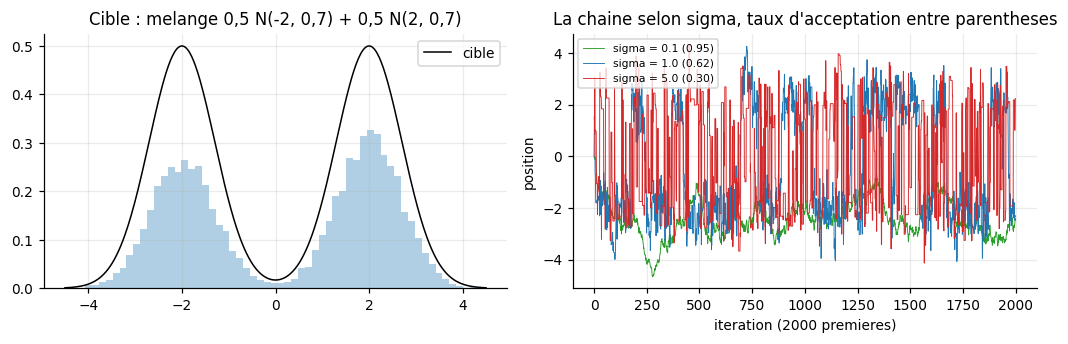

In [14]:
# Graine fixe : la chaine de Markov est reproductible d'une execution a l'autre.
RNG_MH = np.random.default_rng(7)


def log_cible(x):
    """Log-densite (non normalisee) d'un melange de deux gaussiennes."""
    # Melange equipondere de deux gaussiennes d'ecart-type 0.7, centrees en -2 et +2.
    return np.log(0.5 * np.exp(-0.5 * ((x + 2.0) / 0.7) ** 2) +
                  0.5 * np.exp(-0.5 * ((x - 2.0) / 0.7) ** 2))


def metropolis(sigma, pas_total=20000, x0=0.0, rng=None):
    """Metropolis-Hastings a proposition gaussienne centree sur l'etat courant."""
    rng = rng or RNG_MH
    x = x0
    chaine = np.empty(pas_total)
    acceptes = 0
    for i in range(pas_total):
        proposition = x + rng.normal(0.0, sigma)
        # Proposition symetrique : le rapport d'acceptation se reduit a la cible, sans terme de proposition.
        log_rapport = log_cible(proposition) - log_cible(x)
        if np.log(rng.random()) < log_rapport:
            x = proposition
            acceptes += 1
        chaine[i] = x
    return chaine, acceptes / pas_total


SIGMAS = [0.1, 1.0, 5.0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.2))
grille_mh = np.linspace(-4.5, 4.5, 400)
ax1.plot(grille_mh, np.exp(log_cible(grille_mh)), color="black", linewidth=1.0,
         label="cible")
ax1.set_title("Cible : melange 0,5 N(-2, 0,7) + 0,5 N(2, 0,7)")
ax1.legend()

for sigma, couleur in zip(SIGMAS, ("tab:green", "tab:blue", "tab:red")):
    chaine, taux = metropolis(sigma)
    # Les 2000 premieres iterations sont du chauffage (burn-in) et sont exclues des statistiques.
    part_gauche = float((chaine[2000:] < 0.0).mean())
    ax2.plot(chaine[:2000], linewidth=0.6, color=couleur, label=f"sigma = {sigma} ({taux:.2f})")
    print(f"sigma = {sigma:<4} -> taux d'acceptation = {taux:.3f}, "
          f"temps passe dans le mode de gauche = {part_gauche:.3f}")
    if sigma == 1.0:
        ax1.hist(chaine[2000:], bins=60, density=True, alpha=0.35, color=couleur,
                 label="echantillons (sigma = 1.0)")
ax2.set_xlabel("iteration (2000 premieres)")
ax2.set_ylabel("position")
ax2.set_title("La chaine selon sigma, taux d'acceptation entre parentheses")
ax2.legend(fontsize=7)
fig.tight_layout()
plt.show()

### Lecture du résultat

Le taux d'acceptation s'effondre quand la proposition s'élargit : **0.953** à
`sigma = 0.1`, **0.625** à `sigma = 1.0`, **0.305** à `sigma = 5.0`. Les deux excès
échouent pour des raisons opposées — un `sigma` trop petit accepte presque tout mais avance à pas
de fourmi (la chaîne reste collée à son point de départ) ; un `sigma` trop grand propose des sauts
que la cible refuse presque toujours (la chaîne piétine). D'où la règle empirique d'un taux
d'acceptation intermédiaire : la valeur du **quart**, souvent citée pour une proposition
gaussienne, est un résultat asymptotique de grande dimension — en dimension 1, l'optimum se
situe plus haut.

Le panneau de droite le montre directement, et il faut le lire en temps de séjour : à
`sigma = 1.0`, la chaîne passe **0.46** de son temps dans le mode de gauche — la moitié,
comme la cible le demande — contre **0.12** seulement à `sigma = 0.1`. Elle explore,
donc, mais elle sous-représente massivement une moitié de la distribution : l'échantillon est
biaisé, et aucune moyenne calculée dessus ne vaut celle qu'on cherche.

**À manipuler.** Descendez sous `sigma = 0.2` puis montez au-delà de `4.0`, en regardant le taux
d'acceptation **et** l'histogramme. Un taux élevé n'est pas un bon signe : il faut un taux
intermédiaire et un histogramme qui recouvre la cible.

In [15]:
# Callback du widget : rejoue une chaine courte et compare ses echantillons a la cible.
def _montre_metropolis(sigma=1.0):
    rng_local = np.random.default_rng(7)
    chaine, taux = metropolis(sigma, pas_total=8000, rng=rng_local)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 2.8))
    ax1.plot(chaine[:1500], linewidth=0.6)
    ax1.set_title(f"sigma = {sigma:.2f} -- taux d'acceptation {taux:.3f}")
    ax1.set_xlabel("iteration")
    # L'histogramme exclut le burn-in (1000 premiers pas) et se superpose a la densite cible.
    ax2.hist(chaine[1000:], bins=60, density=True, alpha=0.6)
    ax2.plot(grille_mh, np.exp(log_cible(grille_mh)), color="black", linewidth=1.0)
    ax2.set_title("echantillons contre la cible")
    plt.show()


if BATCH_MODE:
    _chaine, _taux = metropolis(1.0, pas_total=8000, rng=np.random.default_rng(7))
    print(f"Mode batch : widget non affiche. A sigma = 1.0, taux d'acceptation = {_taux:.3f}")
else:
    interact(_montre_metropolis,
             sigma=FloatSlider(value=1.0, min=0.05, max=6.0, step=0.05, description="sigma"))

Mode batch : widget non affiche. A sigma = 1.0, taux d'acceptation = 0.623


### Exercice 2 — estimer la cible par blocs

Un échantillonneur de Metropolis ne rend pas des tirages indépendants : deux positions voisines
sont corrélées. Comparer naïvement la moyenne de la chaîne à la vraie moyenne sous-estime
l'incertitude.

**Objectif.** Écrire `moyenne_par_blocs(chaine, taille_bloc)` qui découpe la chaîne en blocs
contigus, calcule la moyenne de chaque bloc, puis renvoie la moyenne de ces moyennes et l'écart
type de cette moyenne (écart type des moyennes de blocs divisé par la racine du nombre de blocs).

**Indices.**
- `# Etape 1` : brûler les 1000 premiers pas (`chaine[1000:]`).
- `# Etape 2` : découper en blocs de `taille_bloc` et écarter le dernier bloc incomplet.
- `# Etape 3` : `np.std(moyennes, ddof=1) / np.sqrt(len(moyennes))`.

In [16]:
def moyenne_par_blocs(chaine, taille_bloc=500):
    """Moyenne de la chaine et erreur type, estimees par blocs contigus."""
    # TODO etudiant : implementer les trois etapes decrites ci-dessus.
    moyenne = None
    erreur_type = None
    return moyenne, erreur_type


_chaine_exemple, _ = metropolis(1.0, pas_total=8000, rng=np.random.default_rng(7))
_moy, _err = moyenne_par_blocs(_chaine_exemple)
print("Exercice a completer")
print(f"moyenne = {_moy}, erreur type = {_err}")

Exercice a completer
moyenne = None, erreur type = None


## 7. La température du recuit simulé

*Série d'origine : Search.*

Le recuit simulé accepte parfois une dégradation pour échapper à un optimum local. La
température fixe le prix de cette tolérance : `exp(-écart / T)`. Chaude, la marche erre ; froide,
elle ne bouge plus. Ce qui distingue le recuit d'une descente gloutonne, c'est cette probabilité
d'accepter du moins bon — et le programme de refroidissement qui l'éteint.

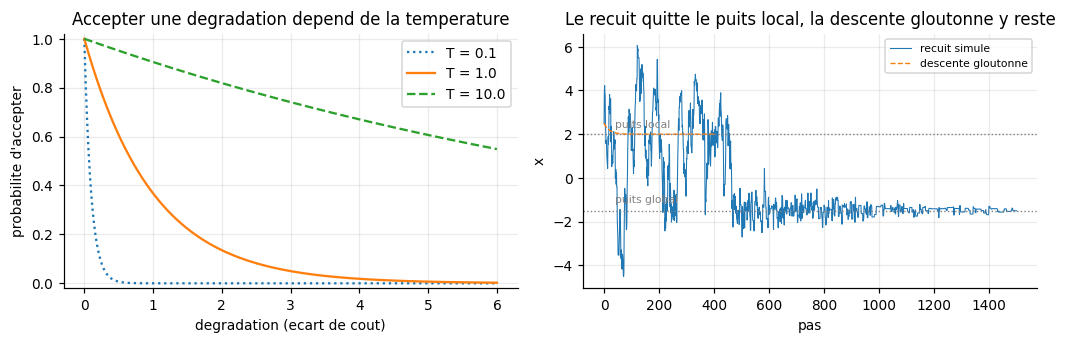

T = 0.1   -> P(accepter un ecart de 1) = 0.000
T = 1.0   -> P(accepter un ecart de 1) = 0.368
T = 10.0  -> P(accepter un ecart de 1) = 0.905
refroidissement 6.0 x 0.995^1500 -> T final = 0.0033
recuit simule     : x final = -1.503, cout final = 0.000
descente gloutonne: x final = +2.000, cout final = 0.600


In [17]:
ECARTS = np.linspace(0.0, 6.0, 300)
TEMPERATURES_RECUIT = [0.1, 1.0, 10.0]


def probabilite_acceptation(ecart, temperature):
    """P(accepter une degradation d'ecart donne), formule de Metropolis."""
    return np.exp(-ecart / temperature)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.2))
for temperature, style in zip(TEMPERATURES_RECUIT, (":", "-", "--")):
    ax1.plot(ECARTS, probabilite_acceptation(ECARTS, temperature), linestyle=style,
             label=f"T = {temperature}")
ax1.set_xlabel("degradation (ecart de cout)")
ax1.set_ylabel("probabilite d'accepter")
ax1.set_title("Accepter une degradation depend de la temperature")
ax1.set_ylim(-0.02, 1.02)
ax1.legend()

# Paysage a deux puits : le global en x = -1.5 (cout 0), le local en x = 2.0 (cout 0.6).
def cout(x):
    return np.minimum(0.5 * (x + 1.5) ** 2, 0.25 * (x - 2.0) ** 2 + 0.6)


def descente_gloutonne(x0=2.5, pas=0.1, iterations=400):
    '''Descente de gradient pure : elle ne peut que descendre.'''
    x = x0
    trace = [x]
    for _ in range(iterations):
        pente = (cout(x + 1e-4) - cout(x - 1e-4)) / 2e-4
        x = x - pas * float(pente)
        trace.append(float(x))
    return np.array(trace)


def recuit(x0=2.5, t0=6.0, refroidissement=0.995, pas_total=1500, sigma=0.7, graine=3):
    '''Recuit simule : accepte une degradation avec la probabilite exp(-ecart / T).'''
    rng = np.random.default_rng(graine)
    x = x0
    temperature = t0
    trace = [x]
    for _ in range(pas_total):
        proposition = x + rng.normal(0.0, sigma)
        ecart = float(cout(proposition) - cout(x))
        if ecart <= 0 or rng.random() < np.exp(-ecart / temperature):
            x = proposition
        trace.append(float(x))
        temperature *= refroidissement
    return np.array(trace), temperature


marche, temperature_finale = recuit()
gloutonne = descente_gloutonne()
ax2.plot(marche, linewidth=0.7, label="recuit simule")
ax2.plot(gloutonne, linewidth=0.9, linestyle="--", label="descente gloutonne")
ax2.axhline(-1.5, linestyle=":", color="gray", linewidth=0.9)
ax2.axhline(2.0, linestyle=":", color="gray", linewidth=0.9)
ax2.annotate("puits global", xy=(40, -1.5), xytext=(40, -1.15), fontsize=7, color="gray")
ax2.annotate("puits local", xy=(40, 2.0), xytext=(40, 2.3), fontsize=7, color="gray")
ax2.set_xlabel("pas")
ax2.set_ylabel("x")
ax2.set_title("Le recuit quitte le puits local, la descente gloutonne y reste")
ax2.legend(fontsize=7)
fig.tight_layout()
plt.show()

for temperature_valeur in TEMPERATURES_RECUIT:
    print(f"T = {temperature_valeur:<5} -> P(accepter un ecart de 1) = "
          f"{probabilite_acceptation(1.0, temperature_valeur):.3f}")
print(f"refroidissement 6.0 x 0.995^1500 -> T final = {temperature_finale:.4f}")
print(f"recuit simule     : x final = {marche[-1]:+.3f}, cout final = {float(cout(marche[-1])):.3f}")
print(f"descente gloutonne: x final = {gloutonne[-1]:+.3f}, cout final = {float(cout(gloutonne[-1])):.3f}")

### Lecture du résultat

Pour un écart de coût de `1`, la probabilité d'accepter vaut **0.0000** à `T = 0.1`,
**0.368** à `T = 1.0` et **0.905** à `T = 10.0`. À froid, le recuit se comporte comme une
descente pure et refuse toute dégradation ; à chaud, il accepte presque tout et se comporte comme
une marche aléatoire.

Le panneau de droite est la démonstration. Sur ce paysage, le puits global est en `x = -1.5`
(coût `0`) et le puits local en `x = 2.0` (coût `0.6`). Partis tous deux de `x = 2.5`, les deux
algorithmes divergent : la **descente gloutonne** finit en `x = ` **+2.000** avec un coût de
**0.600** — elle est enfermée dans le puits local, et aucune itération supplémentaire ne
l'en fera sortir, puisque toute direction y est montante. Le **recuit**, lui, finit en
`x = ` **-1.503** avec un coût de **0.000** : il a accepté des dégradations tant que
`T` était grande, ce qui lui a permis de franchir la barrière, puis le refroidissement
(`6.0 × 0.995^1500`, soit `T = ` **0.0033** à l'arrivée) l'a figé dans le bon puits.

C'est l'idée du recuit : **la température n'est pas un réglage fixe, c'est un programme**. Ce qui
compte est la vitesse à laquelle elle décroît — trop vite, on se fige dans un puits local ; trop
lentement, on n'a jamais le temps de se figer.

**À manipuler.** La courbe est une exponentielle décroissante en l'écart, d'autant plus étalée que
`T` est grand. Regardez le point où `P = 0,5` : sa position est `T × ln 2`. Doubler `T` double
l'écart toléré.

In [18]:
# Callback du widget : probabilite d'accepter une degradation, pour une temperature donnee.
def _montre_recuit(temperature=1.0):
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    ax.plot(ECARTS, probabilite_acceptation(ECARTS, temperature))
    ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("degradation")
    ax.set_ylabel("probabilite d'accepter")
    ax.set_title(f"T = {temperature:.2f} -- P(ecart 1) = "
                 f"{probabilite_acceptation(1.0, temperature):.3f}, "
                 f"P(ecart 3) = {probabilite_acceptation(3.0, temperature):.3f}")
    plt.show()


if BATCH_MODE:
    print(f"Mode batch : widget non affiche. A T = 1.0, P(ecart 1) = "
          f"{probabilite_acceptation(1.0, 1.0):.3f}, P(ecart 3) = "
          f"{probabilite_acceptation(3.0, 1.0):.3f}")
else:
    interact(_montre_recuit,
             temperature=FloatSlider(value=1.0, min=0.05, max=10.0, step=0.05, description="T"))

Mode batch : widget non affiche. A T = 1.0, P(ecart 1) = 0.368, P(ecart 3) = 0.050


## 8. Epsilon-greedy sur un bandit

*Série d'origine : RL.*

Un bandit à cinq bras résume le dilemme de l'apprentissage par renforcement : exploiter
ce qu'on croit bon, ou explorer pour vérifier. `epsilon` est la part des tirages consacrée à
l'exploration. Le regret — l'écart cumulé au bras optimal — mesure le prix des deux erreurs :
explorer trop peu ou explorer trop.

epsilon = 0.00 -> regret cumule a t = 200 :    21.88
epsilon = 0.01 -> regret cumule a t = 200 :    20.48


epsilon = 0.05 -> regret cumule a t = 200 :    18.71
epsilon = 0.10 -> regret cumule a t = 200 :    18.78
epsilon = 0.30 -> regret cumule a t = 200 :    24.42
epsilon = 0.50 -> regret cumule a t = 200 :    29.58


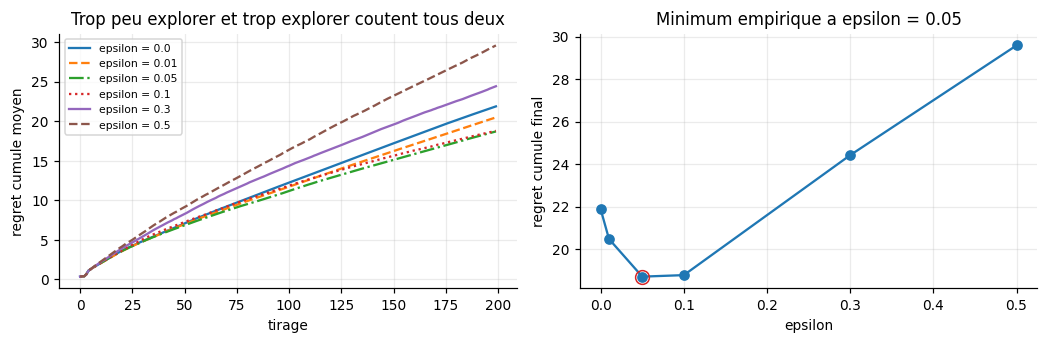

minimum empirique : epsilon = 0.05, regret 18.71
ecart de regret entre epsilon = 0.10 et le minimum : 0.07


In [19]:
# Cinq bras : moyennes vraies des recompenses, le bras 2 (0.55) est le meilleur.
MOYENNES = np.array([0.20, 0.50, 0.55, 0.30, 0.10])
# Bruit gaussien d'ecart-type 1.0 applique a chaque recompense observee.
BRUIT = 1.0
PAS = 200
# 200 tirages par repetition, moyenne sur 200 repetitions independantes pour lisser le regret.
REPETITIONS = 200
EPSILONS = [0.0, 0.01, 0.05, 0.10, 0.30, 0.50]


def simule_epsilon(epsilon, graine=11):
    """Regret cumule moyen de epsilon-greedy sur 200 repetitions independantes."""
    rng = np.random.default_rng(graine)
    n_bras = len(MOYENNES)
    estimations = np.zeros((REPETITIONS, n_bras))
    comptes = np.zeros((REPETITIONS, n_bras))
    regret = np.zeros((REPETITIONS, PAS))
    optimal = MOYENNES.max()
    for t in range(PAS):
        # Initialisation : chaque bras est tire une fois avant de commencer a exploiter.
        if t < n_bras:
            choix = np.full(REPETITIONS, t)
        else:
            explore = rng.random(REPETITIONS) < epsilon
            aleatoire = rng.integers(0, n_bras, REPETITIONS)
            glouton = np.argmax(estimations, axis=1)
            choix = np.where(explore, aleatoire, glouton)
        recompense = MOYENNES[choix] + rng.normal(0.0, BRUIT, REPETITIONS)
        comptes[np.arange(REPETITIONS), choix] += 1
        # Moyenne incrementale : estimation += (recompense - estimation) / comptes.
        estimations[np.arange(REPETITIONS), choix] += (
            recompense - estimations[np.arange(REPETITIONS), choix]
        ) / comptes[np.arange(REPETITIONS), choix]
        # Regret : ecart entre la moyenne du meilleur bras et celle du bras joue.
        regret[:, t] = optimal - MOYENNES[choix]
    return regret.cumsum(axis=1).mean(axis=0)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.2))
regrets_finaux = []
for epsilon, style in zip(EPSILONS, ("-", "--", "-.", ":", "-", "--")):
    courbe = simule_epsilon(epsilon)
    regrets_finaux.append(float(courbe[-1]))
    ax1.plot(courbe, linestyle=style, label=f"epsilon = {epsilon}")
    print(f"epsilon = {epsilon:<4.2f} -> regret cumule a t = 200 : {courbe[-1]:8.2f}")
ax1.set_xlabel("tirage")
ax1.set_ylabel("regret cumule moyen")
ax1.set_title("Trop peu explorer et trop explorer coutent tous deux")
ax1.legend(fontsize=7)

ax2.plot(EPSILONS, regrets_finaux, marker="o")
meilleur_epsilon = int(np.argmin(regrets_finaux))
ax2.plot(EPSILONS[meilleur_epsilon], regrets_finaux[meilleur_epsilon], marker="o",
         markersize=9, markerfacecolor="none", markeredgecolor="tab:red")
ax2.set_xlabel("epsilon")
ax2.set_ylabel("regret cumule final")
ax2.set_title(f"Minimum empirique a epsilon = {EPSILONS[meilleur_epsilon]}")
fig.tight_layout()
plt.show()

print(f"minimum empirique : epsilon = {EPSILONS[meilleur_epsilon]}, "
      f"regret {regrets_finaux[meilleur_epsilon]:.2f}")
print(f"ecart de regret entre epsilon = 0.10 et le minimum : "
      f"{regrets_finaux[3] - regrets_finaux[2]:.2f}")

### Lecture du résultat

Le regret cumulé en 200 tirages vaut **21.88** à `epsilon = 0` (jamais d'exploration),
**20.48** à `epsilon = 0.01`, et **29.58** à `epsilon = 0.5`. Le minimum empirique
tombe à **epsilon = 0.05**, avec **18.71**.

L'optimum est **plat** : à `epsilon = 0.10`, le regret vaut **18.78**, à **0.07**
du minimum de **18.71** — moins d'un demi pour cent sur un regret de près de dix-neuf.
Sur 200 tirages et 200 répétitions, cet écart est dans le bruit — la figure ne permet pas de les départager, et il serait malhonnête d'affirmer
que `0.05` est « le » bon réglage. Ce que la courbe établit solidement, c'est la forme : un minimum
large autour de quelques centièmes, et une dégradation nette vers les deux bouts.

Les deux extrêmes échouent pour des raisons symétriques. À `epsilon = 0`, l'algorithme joue le
premier bras qui a bien voulu paraître bon, et n'en sort jamais : il paie indéfiniment son erreur
initiale. À `epsilon = 0.5`, il consacre un tirage sur deux à un bras au hasard. L'optimum est
entre les deux, et sa position dépend de l'horizon : ce qui est optimal sur 200 tirages ne l'est
pas sur 20 000.

**À manipuler.** Le widget montre une seule répétition, donc une courbe bruitée — c'est le
contre-exemple de la figure : un regret n'est lisible qu'en moyenne sur beaucoup de répétitions.
Le compteur de bras joués, lui, est directement interprétable.

In [20]:
# Callback du widget : rejoue epsilon-greedy sur une seule repetition (pas la moyenne sur 200).
def _montre_epsilon(epsilon=0.10):
    rng = np.random.default_rng(11)
    n_bras = len(MOYENNES)
    estimations = np.zeros(n_bras)
    comptes = np.zeros(n_bras)
    regret = np.zeros(PAS)
    optimal = MOYENNES.max()
    for t in range(PAS):
        if t < n_bras:
            choix = t
        elif rng.random() < epsilon:
            choix = int(rng.integers(0, n_bras))
        else:
            choix = int(np.argmax(estimations))
        recompense = MOYENNES[choix] + rng.normal(0.0, BRUIT)
        comptes[choix] += 1
        estimations[choix] += (recompense - estimations[choix]) / comptes[choix]
        regret[t] = optimal - MOYENNES[choix]
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    ax.plot(np.cumsum(regret))
    ax.set_xlabel("tirage")
    ax.set_ylabel("regret cumule")
    ax.set_title(f"epsilon = {epsilon:.2f} -- regret final {np.cumsum(regret)[-1]:.1f}, "
                 f"bras le plus joue : {int(np.argmax(comptes))}")
    plt.show()


if BATCH_MODE:
    print(f"Mode batch : widget non affiche. A epsilon = 0.10, regret final = "
          f"{simule_epsilon(0.10)[-1]:.2f} (moyenne sur 200 repetitions)")
else:
    interact(_montre_epsilon,
             epsilon=FloatSlider(value=0.10, min=0.0, max=0.6, step=0.01, description="epsilon"))

Mode batch : widget non affiche. A epsilon = 0.10, regret final = 18.78 (moyenne sur 200 repetitions)


## 9. L'équilibre de Nash du dilemme du prisonnier

*Série d'origine : GameTheory.*

Deux joueurs choisissent de coopérer ou de faire défection ; la **tentation** `T` est le
gain d'une défection contre un coopérateur. Tant que `T` reste sous la récompense mutuelle `R`,
coopérer est une meilleure réponse ; au-delà, la défection domine quoi que fasse l'autre. Une seule
inégalité suffit à faire basculer le jeu d'un équilibre coopératif vers un équilibre
sous-optimal.

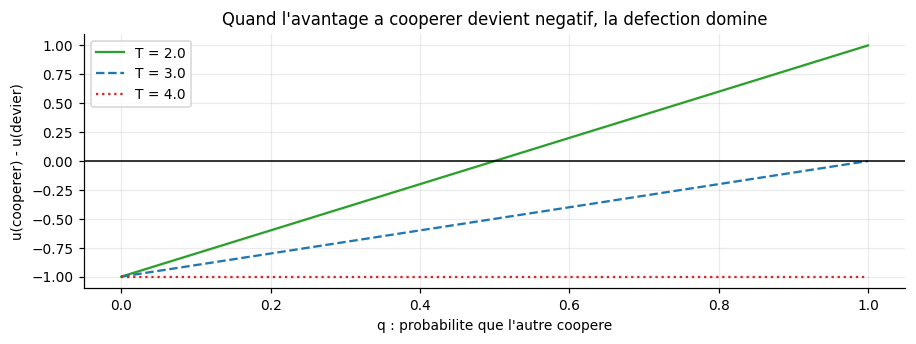

T = 2.0  -> min = -1.000, max = +1.000 : cooperation possible si q > q*
T = 3.0  -> min = -1.000, max = +0.000 : devier ne perd jamais (egalite en q = 1)
T = 4.0  -> min = -1.000, max = -1.000 : devier domine pour tout q
seuil theorique T = R = 3.0 ; q* mesure a T = 2.0 : 0.50


In [21]:
R = 3.0  # gain de la cooperation mutuelle
S = 0.0  # gain du dindon
P = 1.0  # gain de la defection mutuelle
TENTATIONS = [2.0, 3.0, 4.0]
Q = np.linspace(0.0, 1.0, 200)


def avantage_cooperer(q, tentation, r=R, s=S, p=P):
    """u(C, q) - u(D, q) : l'avantage a cooperer quand l'autre coopere avec probabilite q."""
    u_cooperer = q * r + (1 - q) * s
    u_devier = q * tentation + (1 - q) * p
    return u_cooperer - u_devier


fig, ax = plt.subplots(figsize=(8.4, 3.2))
for tentation, style, couleur in zip(TENTATIONS, ("-", "--", ":"),
                                     ("tab:green", "tab:blue", "tab:red")):
    ax.plot(Q, avantage_cooperer(Q, tentation), linestyle=style, color=couleur,
            label=f"T = {tentation}")
ax.axhline(0.0, color="black", linewidth=1.0)
ax.set_xlabel("q : probabilite que l'autre coopere")
ax.set_ylabel("u(cooperer) - u(devier)")
ax.set_title("Quand l'avantage a cooperer devient negatif, la defection domine")
ax.legend()
fig.tight_layout()
plt.show()

for tentation in TENTATIONS:
    valeurs = avantage_cooperer(Q, tentation)
    if valeurs.max() < -1e-9:
        verdict = "devier domine pour tout q"
    elif valeurs.max() <= 1e-9:
        verdict = "devier ne perd jamais (egalite en q = 1)"
    else:
        # Zero de l'avantage : q* ou cooperer et devier rapportent autant.
        verdict = "cooperation possible si q > q*"
    print(f"T = {tentation:<4} -> min = {valeurs.min():+.3f}, max = {valeurs.max():+.3f} : {verdict}")
print(f"seuil theorique T = R = {R:.1f} ; q* mesure a T = 2.0 : "
      f"{float(np.interp(0.0, avantage_cooperer(Q, 2.0), Q)):.2f}")

### Lecture du résultat

Le seuil est exactement `T = R = ` **3.0**, et la figure le montre des deux côtés.
À `T = 2.0`, l'avantage à coopérer va de **-1.000** (en `q = 0`, où coopérer contre un
défectueur coûte) à **+1.000** (en `q = 1`, où la coopération est payée `R = 3` contre une
tentation de `2`) : il croise zéro à `q* = ` **0.50**, donc coopérer reste une meilleure
réponse tant que l'autre coopère assez souvent. À `T = 4.0`, l'avantage vaut **-1.000**
**partout** : la défection domine, quel que soit `q`.

Cas limite, `T = 3.0` exactement : l'avantage vaut **+0.000** en `q = 1`. Dévier ne perd
jamais, mais ne gagne rien non plus contre un coopérateur — c'est l'égalité, et l'équilibre
coopératif n'est plus strictement préféré. C'est là que le jeu bascule.

C'est la définition d'un équilibre de Nash lue sur une courbe : un profil est un équilibre si
aucun joueur ne gagne à dévier seul. Pour `T > R`, `(D, D)` est l'unique équilibre et il est
**sous-optimal** — les deux joueurs préféreraient `(C, C)`, mais aucun ne peut y aller seul. C'est
le dilemme du prisonnier, réduit à une inégalité.

**À manipuler.** Le curseur traverse `T = 3` de part et d'autre. Juste en dessous, la coopération
est un équilibre ; juste au-dessus, elle ne l'est plus. Le basculement est brutal — c'est un effet
**à seuil**, pas un effet progressif.

In [22]:
# Callback du widget : avantage a cooperer selon q, avec le zero q* ou cooperer et devier s'equilibrent.
def _montre_nash(tentation=2.0):
    valeurs = avantage_cooperer(Q, tentation)
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    ax.plot(Q, valeurs)
    ax.axhline(0.0, color="black", linewidth=1.0)
    if valeurs.min() < 0 < valeurs.max():
        q_etoile = float(np.interp(0.0, valeurs, Q))
        ax.axvline(q_etoile, linestyle=":", color="gray")
        verdict = f"cooperation si q > {q_etoile:.2f}"
    else:
        verdict = "devier domine" if valeurs.max() <= 0 else "cooperer domine"
    ax.set_title(f"T = {tentation:.2f} (R = 3) -- {verdict}")
    ax.set_xlabel("q : probabilite que l'autre coopere")
    ax.set_ylabel("avantage a cooperer")
    plt.show()


if BATCH_MODE:
    _valeurs = avantage_cooperer(Q, 2.0)
    print(f"Mode batch : widget non affiche. A T = 2.0, avantage max = {_valeurs.max():+.3f}, "
          f"q* = {float(np.interp(0.0, _valeurs, Q)):.2f} ; a T = 4.0 l'avantage est toujours "
          f"negatif (max {avantage_cooperer(Q, 4.0).max():+.3f})")
else:
    interact(_montre_nash,
             tentation=FloatSlider(value=2.0, min=0.0, max=6.0, step=0.1, description="T"))

Mode batch : widget non affiche. A T = 2.0, avantage max = +1.000, q* = 0.50 ; a T = 4.0 l'avantage est toujours negatif (max -1.000)


### Exercice 3 — le seuil de tentation pour un autre jeu

Le seuil `T = R` du carnet supposait `S = 0` et `P = 1`. Changez les gains et la condition change.

**Objectif.** Écrire `seuil_tentation(r, s, p)` qui renvoie la valeur de `T` à partir de laquelle la
défection devient une meilleure réponse pour tout `q`, puis vérifier numériquement le résultat sur
`(R, S, P) = (4.0, 1.0, 2.0)`.

**Indices.**
- `# Etape 1` : l'avantage à coopérer est `q*R + (1-q)*S - (q*T + (1-q)*P)`.
- `# Etape 2` : c'est une fonction affine de `q` ; son maximum est atteint en `q = 1` (si le
  coefficient est positif) ou en `q = 0`.
- `# Etape 3` : la coopération cesse d'être sûre quand l'avantage s'annule en `q = 1`, c'est-à-dire
  quand `T = R`. Vérifiez-le sur les nouvelles valeurs et dites si le seuil dépend de `S` et `P`.

In [23]:
def seuil_tentation(r, s, p):
    """Valeur de T au-dela de laquelle la defection domine pour tout q."""
    # TODO etudiant : implementer les trois etapes decrites ci-dessus.
    seuil = None
    return seuil


_seuil = seuil_tentation(4.0, 1.0, 2.0)
print("Exercice a completer")
print(f"seuil de tentation pour (R, S, P) = (4.0, 1.0, 2.0) : {_seuil}")

Exercice a completer
seuil de tentation pour (R, S, P) = (4.0, 1.0, 2.0) : None


## 10. Le seuil de satisfiabilité 3-SAT

*Série d'origine : Complexity.*

Un problème 3-SAT avec `n` variables et `alpha × n` clauses passe d'une quasi-certitude
d'être satisfiable à une quasi-certitude de ne plus l'être autour de `alpha = 4,26`. C'est une
**transition de phase** : la difficulté n'est pas répartie, elle est concentrée sur une bande
étroite. C'est aussi la démonstration qu'un paramètre purement structurel — le rapport
clauses/variables — gouverne la difficulté d'un problème, indépendamment de sa taille.

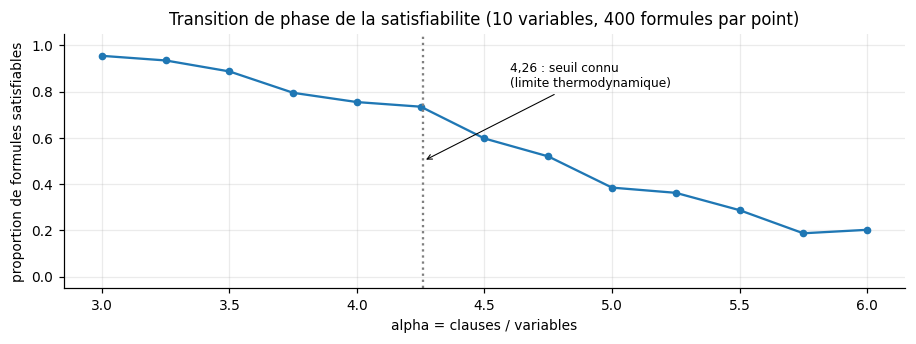

alpha = 3.00 -> proportion satisfiable = 0.955
alpha = 3.25 -> proportion satisfiable = 0.935
alpha = 3.50 -> proportion satisfiable = 0.887
alpha = 3.75 -> proportion satisfiable = 0.795
alpha = 4.00 -> proportion satisfiable = 0.755
alpha = 4.25 -> proportion satisfiable = 0.735
alpha = 4.50 -> proportion satisfiable = 0.598
alpha = 4.75 -> proportion satisfiable = 0.520
alpha = 5.00 -> proportion satisfiable = 0.385
alpha = 5.25 -> proportion satisfiable = 0.362
alpha = 5.50 -> proportion satisfiable = 0.287
alpha = 5.75 -> proportion satisfiable = 0.188
alpha = 6.00 -> proportion satisfiable = 0.203
bascule mesuree sous 0,5 : alpha = 5.00
seuil connu (limite thermodynamique) : alpha = 4.26
instance : 10 variables, 400 formules par point, 1024 assignations enumerees


In [24]:
RNG_SAT = np.random.default_rng(5)
N_VARIABLES = 10
N_FORMULES = 400
ALPHAS = np.linspace(3.0, 6.0, 13)
ASSIGNATIONS = (np.arange(2 ** N_VARIABLES)[:, None] >> np.arange(N_VARIABLES)) & 1
ASSIGNATIONS = ASSIGNATIONS.astype(bool)


def echantillonne_sat(alpha, n_formules=N_FORMULES, rng=None):
    """Proportion de formules 3-SAT satisfiables a m = alpha * n clauses, par force brute."""
    rng = rng or RNG_SAT
    n_clauses = int(round(alpha * N_VARIABLES))
    satisfiables = 0
    exemple_insatisfiable = None
    for _ in range(n_formules):
        variables = rng.integers(0, N_VARIABLES, size=(n_clauses, 3))
        signes = rng.random((n_clauses, 3)) < 0.5  # True = litteral positif
        # Une clause est satisfaite si au moins un litteral l'est.
        litteraux = ASSIGNATIONS[:, variables]  # (2^n, m, 3)
        litteraux = np.where(signes, litteraux, ~litteraux)
        clauses_satisfaites = litteraux.any(axis=2)  # (2^n, m)
        if clauses_satisfaites.all(axis=1).any():
            satisfiables += 1
        elif exemple_insatisfiable is None:
            exemple_insatisfiable = (variables.copy(), signes.copy())
    return satisfiables / n_formules


proportions = np.array([echantillonne_sat(alpha) for alpha in ALPHAS])
bascule = float(ALPHAS[int(np.argmax(proportions < 0.5))]) if (proportions < 0.5).any() else float("nan")

fig, ax = plt.subplots(figsize=(8.4, 3.2))
ax.plot(ALPHAS, proportions, marker="o", markersize=4)
ax.axvline(4.26, linestyle=":", color="gray")
ax.annotate("4,26 : seuil connu\n(limite thermodynamique)", xy=(4.26, 0.5), xytext=(4.6, 0.82),
            fontsize=8, arrowprops={"arrowstyle": "->", "linewidth": 0.7})
ax.set_xlabel("alpha = clauses / variables")
ax.set_ylabel("proportion de formules satisfiables")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"Transition de phase de la satisfiabilite ({N_VARIABLES} variables, "
             f"{N_FORMULES} formules par point)")
fig.tight_layout()
plt.show()

for alpha, proportion in zip(ALPHAS, proportions):
    print(f"alpha = {alpha:.2f} -> proportion satisfiable = {proportion:.3f}")
print(f"bascule mesuree sous 0,5 : alpha = {bascule:.2f}")
print("seuil connu (limite thermodynamique) : alpha = 4.26")
print(f"instance : {N_VARIABLES} variables, {N_FORMULES} formules par point, "
      f"{2 ** N_VARIABLES} assignations enumerees")

### Lecture du résultat

À `alpha = 3`, la proportion de formules satisfiables vaut **0.955** ; à `alpha = 6`, elle
vaut **0.203**. Entre les deux, la bascule mesurée sous `0,5` tombe à
`alpha = ` **5.00**, à comparer au seuil connu de **4.26** pour la limite
thermodynamique.

L'écart est attendu et instructif : avec **10** variables seulement, la transition
n'est pas une marche verticale mais une pente étalée sur toute la plage — **0.887** à
`alpha = 3,50`, **0.598** à `alpha = 4,50`, **0.385** à `alpha = 5,00` — et
**400** formules par point ajoutent leur bruit d'échantillonnage. Le seuil de
**4.26** est une limite quand `n` tend vers l'infini : à taille finie, la pente existe,
et c'est en grandissant que `n` la resserre autour de ce point.
La notion à retenir est donc double — il existe bien une **bande étroite** où la satisfiabilité
bascule, et cette bande se **raidit avec la taille** ; sur un problème de quelques variables, on
voit une pente, pas un saut. Un problème peut rester facile presque partout et devenir difficile
sur une bande étroite, et cette bande est exactement là où les solveurs travaillent.

**À manipuler.** Déplacez `alpha` autour de `4,26` : chaque point est lui-même bruité (100
formules), donc la proportion ne descend pas régulièrement d'un pas à l'autre. La transition est
**nette en probabilité**, pas en réalisation : une formule tirée à `alpha = 4,3` peut très bien
être satisfiable, et c'est précisément pour cela qu'on parle de probabilité et non de bascule
déterministe.

In [25]:
# Callback du widget : proportion satisfiable mesuree a un alpha donne, replacee sur la courbe complete.
def _montre_sat(alpha=4.26):
    proportion = echantillonne_sat(alpha, n_formules=100, rng=np.random.default_rng(5))
    fig, ax = plt.subplots(figsize=(7.0, 2.8))
    # La courbe grise rappelle le balayage complet ; le point rouge marque l'alpha choisi.
    ax.plot(ALPHAS, proportions, marker="o", markersize=4, color="lightgray")
    ax.plot(alpha, proportion, marker="o", markersize=10, markerfacecolor="none",
            markeredgecolor="tab:red")
    ax.axvline(4.26, linestyle=":", color="gray")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("alpha = clauses / variables")
    ax.set_ylabel("proportion satisfiable (100 formules)")
    ax.set_title(f"alpha = {alpha:.2f} -> proportion mesuree {proportion:.2f}")
    plt.show()


if BATCH_MODE:
    _proportion = echantillonne_sat(4.26, n_formules=100, rng=np.random.default_rng(5))
    print(f"Mode batch : widget non affiche. A alpha = 4.26, proportion satisfiable = "
          f"{_proportion:.2f} (100 formules)")
else:
    interact(_montre_sat,
             alpha=FloatSlider(value=4.26, min=2.0, max=6.0, step=0.05, description="alpha"))

Mode batch : widget non affiche. A alpha = 4.26, proportion satisfiable = 0.67 (100 formules)


## À retenir

| # | Notion | Série | Paramètre | Type d'effet | Ce que la figure a établi |
|---|--------|-------|-----------|--------------|---------------------------|
| 1 | Température d'échantillonnage | GenAI | `T` | monotone | Entropie croissante de `T = 0.2` à `T = 1.5` |
| 2 | Top-p | GenAI | `p` | monotone, non linéaire | Le noyau grandit plus vite que la masse qu'il gagne |
| 3 | Pas d'apprentissage | ML | pas | à optimum | Divergence au-delà de `2 / f''` |
| 4 | Seuil de décision | ML | seuil | à optimum | Précision et rappel s'échangent, F1 a un maximum |
| 5 | Mise à jour Beta | Probas | `(a, b)` | monotone | La largeur de l'intervalle se resserre avec les données |
| 6 | Acceptation Metropolis | Probas | `sigma` | à optimum | Le taux utile est intérieur : à `sigma = 1.0` (taux 0.625), la chaîne partage son temps entre les deux modes |
| 7 | Température du recuit | Search | `T` | monotone | La tolérance aux dégradations décroît avec la température |
| 8 | Epsilon-greedy | RL | `epsilon` | à optimum | Le regret a un minimum intérieur |
| 9 | Nash du dilemme | GameTheory | `T` | à seuil | Coopération perdue dès que `T > R` |
| 10 | Satisfiabilité 3-SAT | Complexity | `alpha` | à seuil | Pente autour de `4,26`, qui se raidit avec la taille |

Trois formes d'effet, trois façons de lire un paramètre :

- **monotone** : on sait dans quel sens ça va, il reste à savoir à quelle vitesse ;
- **à optimum** : il existe une valeur intermédiaire, et la trouver est le travail ;
- **à seuil** : il ne se passe presque rien, puis la réponse change de camp — et la position du
  seuil est la question.

Ce classement n'est pas propre à ces dix notions : il vaut pour la plupart des hyperparamètres
d'un système d'apprentissage. Savoir dans quelle classe tombe celui qu'on règle évite deux
erreurs coûteuses — chercher un optimum là où il n'y en a pas, et pousser une valeur monotone
jusqu'à ce que quelque chose casse.

## Vérifiez votre compréhension

<details><summary>1. Pourquoi une température <code>T = 0.2</code> ne rend-elle pas le modèle
plus « précis » ?</summary>

Parce qu'elle ne change pas ce que le modèle sait : elle aplatit ou point les probabilités qu'il
a déjà calculées. À `T = 0.2`, le jeton le plus probable reste le même qu'à `T = 1.5` ; seule la
masse qui lui est attribuée change. Un modèle plus pointu n'est pas un modèle meilleur, il est
seulement plus répétitif.
</details>

<details><summary>2. Un taux d'acceptation de 0,95 dans Metropolis-Hastings est-il une bonne
nouvelle ?</summary>

Non. Un taux très élevé signifie des propositions trop petites : la chaîne accepte presque tout
mais avance à peine, et met un temps prohibitif à explorer la cible. Le taux utile est
intermédiaire — la règle du quart souvent citée vaut pour les grandes dimensions, et en
dimension 1 l'optimum se situe plus haut — et se lit avec l'histogramme, pas seul.
</details>

<details><summary>3. Pourquoi le seuil de Nash ne dépend-il pas des gains <code>S</code> et
<code>P</code> ?</summary>

Parce que la question posée est « la défection domine-t-elle pour **tout** `q` ? ». L'avantage à
coopérer est une fonction affine de `q` ; son maximum est atteint à une extrémité, et l'extrémité
pertinente est `q = 1` — que l'autre coopère. En `q = 1`, la comparaison se réduit à `R` contre
`T` : `S` et `P` ne pèsent que sur les scénarios où l'autre dévie, déjà perdus.
</details>

## Pour aller plus loin

Les dix notions viennent de carnets qui les traitent en profondeur :

| Série | Où chercher |
|-------|-------------|
| GenAI | `MyIA.AI.Notebooks/GenAI/` — génération de texte, décodage et échantillonnage |
| ML | `MyIA.AI.Notebooks/ML/` — optimisation, évaluation et courbes précision-rappel |
| Probas | `MyIA.AI.Notebooks/Probas/` — inférence bayésienne, MCMC et décision |
| Search | `MyIA.AI.Notebooks/Search/` — recuit simulé et métaheuristiques |
| RL | `MyIA.AI.Notebooks/RL/` — bandits, exploration et regret |
| GameTheory | `MyIA.AI.Notebooks/GameTheory/` — équilibres, dilemme du prisonnier |
| Complexity | `MyIA.AI.Notebooks/Complexity/` — 3-SAT et transitions de phase |

Ces carnets portent la théorie ; celui-ci n'en est que le **tableau de bord manipulable**. Une
notion comprise ici se travaille là-bas.